In [2]:
from utils import get_hdf5_files, get_filename, get_continuous_behaviors, get_discrete_states, get_eigenworms, get_kymograph, get_neuronal_traces, get_variance_explained

import os
import math
from matplotlib import pyplot as plt
import numpy as np
import pandas as pd

from sklearn.decomposition import PCA
from sklearn.cross_decomposition import CCA
from sklearn.metrics import r2_score
from sklearn.model_selection import TimeSeriesSplit, StratifiedKFold

from sklearn.linear_model import LinearRegression

import jax
import jax.numpy as jnp
import optax

# GCAMP DATA

In [3]:
path = f'{os.getcwd()}/../data/{os.path.basename(os.getcwd())}/exported_data_/'
hdf5files = get_hdf5_files(path)
filenames = [get_filename(file) for file in hdf5files]
continuous_behaviors = [get_continuous_behaviors(file) for file in hdf5files]
discrete_states = [get_discrete_states(file) for file in hdf5files]
eigenworms = [get_eigenworms(file) for file in hdf5files]
kymographs = [get_kymograph(file) for file in hdf5files]
traces = [get_neuronal_traces(file) for file in hdf5files]

### preprocessing

In [4]:
for i in range(len(filenames)):
	mask = eigenworms[i].notna().all(axis=1)
	#continuous_behaviors[i] = continuous_behaviors[i][mask]
	discrete_states[i] = discrete_states[i][mask]
	eigenworms[i] = eigenworms[i][mask]
	traces[i] = traces[i][mask]

	#kymographs[i] = kymographs[i][mask]
	#filenames[i] = filenames[i][mask]

### HGM

In [5]:
lambda_1, lambda_2, lambda_3 = 1, 1

random_key = jax.random.PRNGKey(0)
optimizer = optax.adam(1e-3)


def init_params_hgm(shape_U, shape_VT, shape_X, shape_X_man):
    return {
        'U': 1E-2 * jax.random.normal(random_key, shape_U),
        'VT': 1E-2 * jax.random.normal(random_key, shape_VT),
        'W1': 1E-2 * jax.random.normal(random_key, shape_X),
        'W2': 1E-2 * jax.random.normal(random_key, shape_X_man)
    }

def predict_hgm(X, B_ll, params):
	U, W1, W2 = params['U'], params['W1'], params['W2']
	X_man = X @ U
	Y_pred = B_ll @ W1 * jax.nn.sigmoid(X_man @ W2)
	return Y_pred

def loss_fn_hgm(params, X, B_ll, B_hl):
	U, VT, W1, W2 = params['U'], params['VT'], params['W1'], params['W2']

	X_man = X @ U

	B_hl_pred = X_man @ VT
	man_loss = jnp.mean((B_hl_pred - B_hl) ** 2)

	Y_pred = B_ll @ W1 * jax.nn.sigmoid(X_man @ W2)

	X_rec = X_man @ jax.numpy.linalg.pinv(U)
	X_res = X - X_rec
	hgm_loss = jnp.mean((Y_pred - X_res) ** 2)

	return lambda_1 * man_loss + lambda_2 * hgm_loss + lambda_3 * jnp.mean((X - X_rec) ** 2)

@jax.jit
def update_hgm(opt_state, params, X, B_ll, B_hl):
    grads = jax.grad(loss_fn_hgm)(params, X, B_ll, B_hl)
    params_updates, opt_state = optimizer.update(grads, opt_state, params)
    params_new = optax.apply_updates(params, params_updates)
    return params_new, opt_state

In [6]:
selection = ['REV', 'VENTRAL_TURN', 'DORSAL_TURN', 'PAUSE']

random_key = jax.random.PRNGKey(0)
optimizer = optax.adam(1e-3)

max_epochs = 500
min_epochs = 10
max_patience = 20

models_params_hgm = list()
models_losses_hgm = list()
models_t_losses_hgm = list()
models_scores_hgm = list()
models_epochs_hgm = list()
for i in range(len(filenames)):
	print(f'{i+1}/{len(filenames)}: {filenames[i]}  ', end='')

	X = traces[i].values
	B_hl = discrete_states[i][selection].values
	B_ll = eigenworms[i].values

	n_neurons = X.shape[1]
	n_dimensions = 2
	n_behaviors_hl = B_hl.shape[1]
	n_behaviors_ll = B_ll.shape[1]


	cv = StratifiedKFold(n_splits=5)
	splits = list(cv.split(np.zeros(traces[i].shape[0]), discrete_states[i]['REV'].values))

	losses_per_split = list()
	t_losses_per_split = list()
	scores_per_split = list()
	epochs_per_split = list()
	for train, test in splits:
		X_train, X_test = X[train], X[test]
		B_hl_train, B_hl_test = B_hl[train], B_hl[test]
		B_ll_train, B_ll_test = B_ll[train], B_ll[test]

		params = init_params_hgm((n_neurons, n_dimensions), (n_dimensions, n_behaviors_hl), (n_behaviors_ll, n_neurons), (n_dimensions, n_neurons))
		opt_state = optimizer.init(params)

		best_params = params
		best_loss = 1.1

		patience = 0
		losses = [loss_fn_hgm(params, X_test, B_ll_test, B_hl_test).item()]
		t_losses = [loss_fn_hgm(params, X_train, B_ll_train, B_hl_train).item()]
		for epoch in range(max_epochs):
			params, opt_state = update_hgm(opt_state, params, X, B_ll, B_hl)
			loss = loss_fn_hgm(params, X_test, B_ll_test, B_hl_test).item()
			t_loss = loss_fn_hgm(params, X_train, B_ll_train, B_hl_train).item()

			# early stopping =============
			if epoch > min_epochs:
				if loss < best_loss:
					losses.append(loss)
					t_losses.append(t_loss)
					best_loss = loss
					best_params = params
					patience = 0
				else:
					patience += 1
					if patience > max_patience:
						losses_padding = [best_loss for _ in range(max_epochs - len(losses) + 1)]
						t_losses_padding = [t_losses[-1] for _ in range(max_epochs - len(t_losses) + 1)]
						losses = losses + losses_padding
						t_losses = t_losses + t_losses_padding
						epochs_per_split.append(epoch + 1)
						break
					losses.append(loss)
					t_losses.append(t_loss)
			# ============================
			else:
				losses.append(loss)
				t_losses.append(t_loss)
		losses_per_split.append(losses)
		t_losses_per_split.append(t_losses)

		U = params['U']
		X_man = X_test @ U
		X_rec = X_man @ jax.numpy.linalg.pinv(U)
		X_res = X_test - X_rec
		Y_pred = predict_hgm(X_test, B_ll_test, params)
		score_per_neuron = [r2_score(trace, trace_pred) for trace, trace_pred in zip(X_res.T, Y_pred.T)]
		scores_per_split.append(score_per_neuron)

		if len(epochs_per_split) == 0:
			epochs_per_split.append(max_epochs)

	models_t_losses_hgm.append(np.array(t_losses_per_split))
	models_losses_hgm.append(np.array(losses_per_split))

	scores_per_split_avg = np.array(scores_per_split).mean(axis=0)
	models_scores_hgm.append(scores_per_split_avg)

	epochs_per_split_avg = np.array(epochs_per_split).mean()
	models_epochs_hgm.append(epochs_per_split_avg)

1/34: ZIM2165_Gcamp7b_worm3-2022_11_28_no_image_data  2/34: ZIM2165_Gcamp7b_worm3-2022-12-10_no_image_data  3/34: ZIM2165_Gcamp7b_worm6-2022-12-10_no_image_data  4/34: ZIM2165_Gcamp7b_worm7-2022-12-10_no_image_data  5/34: 2024-01-17_13-02_wt_FM_worm2_again-2024-01-17_no_image_data  6/34: ZIM2165_Gcamp7b_worm9-2022-12-05_no_image_data  7/34: 2024-01-30_16-32_wt_worm1-2024-01-30_no_image_data  8/34: ZIM2165_Gcamp7b_worm4-2022_11_28_no_image_data  9/34: 2023-11-21_12-39_wt_worm1-2023-11-21_no_image_data  10/34: ZIM2165_Gcamp7b_worm8-2022-12-10_no_image_data  11/34: ZIM2165_Gcamp7b_worm1-2022-12-10_no_image_data  12/34: ZIM2165_Gcamp7b_worm1-2022-11-30_no_image_data  13/34: ZIM2165_Gcamp7b_worm2-2022-12-10_no_image_data  14/34: ZIM2165_Gcamp7b_worm4-2022-12-10_no_image_data  15/34: 2023-11-30_14-31_wt_worm5_FM-2023-11-30_no_image_data  16/34: ZIM2165_Gcamp7b_worm6-2022_11_28_no_image_data  17/34: 2022-11-23_worm9_no_image_data  18/34: 2024-01-11_16-42_wt_FM_worm06-2024-01-11_no_image_data 

### GLM

In [7]:
lambda_1, lambda_2 = 1, 1

random_key = jax.random.PRNGKey(0)
optimizer = optax.adam(1e-3)


def init_params_glm(shape_U, shape_VT, shape_X):
    return {
        'U': 1E-2 * jax.random.normal(random_key, shape_U),
        'VT': 1E-2 * jax.random.normal(random_key, shape_VT),
        'W1': 1E-2 * jax.random.normal(random_key, shape_X)
    }

def predict_glm(B_ll, params):
	U, W1 = params['U'], params['W1']
	Y_pred = B_ll @ W1
	return Y_pred

def loss_fn_glm(params, X, B_ll, B_hl):
	U, VT, W1 = params['U'], params['VT'], params['W1']

	X_man = X @ U

	B_hl_pred = X_man @ VT
	man_loss = jnp.mean((B_hl_pred - B_hl) ** 2)

	Y_pred = B_ll @ W1

	X_rec = X_man @ jax.numpy.linalg.pinv(U)
	X_res = X - X_rec
	hgm_loss = jnp.mean((Y_pred - X_res) ** 2)

	return lambda_1 * man_loss + lambda_2 * hgm_loss

@jax.jit
def update_glm(opt_state, params, X, B_ll, B_hl):
    grads = jax.grad(loss_fn_glm)(params, X, B_ll, B_hl)
    params_updates, opt_state = optimizer.update(grads, opt_state, params)
    params_new = optax.apply_updates(params, params_updates)
    return params_new, opt_state

In [8]:
selection = ['REV', 'VENTRAL_TURN', 'DORSAL_TURN', 'PAUSE']

random_key = jax.random.PRNGKey(0)
optimizer = optax.adam(1e-3)

max_epochs = 500
min_epochs = 10
max_patience = 20

models_params_glm = list()
models_losses_glm = list()
models_t_losses_glm = list()
models_scores_glm = list()
models_epochs_glm = list()
for i in range(len(filenames)):
	print(f'{i+1}/{len(filenames)}: {filenames[i]}  ', end='')

	X = traces[i].values
	B_hl = discrete_states[i][selection].values
	B_ll = eigenworms[i].values

	n_neurons = X.shape[1]
	n_dimensions = 2
	n_behaviors_hl = B_hl.shape[1]
	n_behaviors_ll = B_ll.shape[1]


	cv = StratifiedKFold(n_splits=5)
	splits = list(cv.split(np.zeros(traces[i].shape[0]), discrete_states[i]['REV'].values))

	losses_per_split = list()
	t_losses_per_split = list()
	scores_per_split = list()
	epochs_per_split = list()
	for train, test in splits:
		X_train, X_test = X[train], X[test]
		B_hl_train, B_hl_test = B_hl[train], B_hl[test]
		B_ll_train, B_ll_test = B_ll[train], B_ll[test]

		params = init_params_glm((n_neurons, n_dimensions), (n_dimensions, n_behaviors_hl), (n_behaviors_ll, n_neurons))
		opt_state = optimizer.init(params)

		best_params = params
		best_loss = 1.1

		patience = 0
		losses = [loss_fn_glm(params, X_test, B_ll_test, B_hl_test).item()]
		t_losses = [loss_fn_glm(params, X_train, B_ll_train, B_hl_train).item()]
		for epoch in range(max_epochs):
			params, opt_state = update_glm(opt_state, params, X, B_ll, B_hl)
			loss = loss_fn_glm(params, X_test, B_ll_test, B_hl_test).item()
			t_loss = loss_fn_glm(params, X_train, B_ll_train, B_hl_train).item()

			# early stopping =============
			if epoch > min_epochs:
				if loss < best_loss:
					losses.append(loss)
					t_losses.append(t_loss)
					best_loss = loss
					best_params = params
					patience = 0
				else:
					patience += 1
					if patience > max_patience:
						losses_padding = [best_loss for _ in range(max_epochs - len(losses) + 1)]
						t_losses_padding = [t_losses[-1] for _ in range(max_epochs - len(t_losses) + 1)]
						losses = losses + losses_padding
						t_losses = t_losses + t_losses_padding
						epochs_per_split.append(epoch + 1)
						break
					losses.append(loss)
					t_losses.append(t_loss)
			# ============================
			else:
				losses.append(loss)
				t_losses.append(t_loss)
		losses_per_split.append(losses)
		t_losses_per_split.append(t_losses)

		U = params['U']
		X_man = X_test @ U
		X_rec = X_man @ jax.numpy.linalg.pinv(U)
		X_res = X_test - X_rec
		Y_pred = predict_glm(B_ll_test, params)
		score_per_neuron = [r2_score(trace, trace_pred) for trace, trace_pred in zip(X_res.T, Y_pred.T)]
		scores_per_split.append(score_per_neuron)

		if len(epochs_per_split) == 0:
			epochs_per_split.append(max_epochs)

	models_t_losses_glm.append(np.array(t_losses_per_split))
	models_losses_glm.append(np.array(losses_per_split))

	scores_per_split_avg = np.array(scores_per_split).mean(axis=0)
	models_scores_glm.append(scores_per_split_avg)

	epochs_per_split_avg = np.array(epochs_per_split).mean()
	models_epochs_glm.append(epochs_per_split_avg)

1/34: ZIM2165_Gcamp7b_worm3-2022_11_28_no_image_data  2/34: ZIM2165_Gcamp7b_worm3-2022-12-10_no_image_data  3/34: ZIM2165_Gcamp7b_worm6-2022-12-10_no_image_data  4/34: ZIM2165_Gcamp7b_worm7-2022-12-10_no_image_data  5/34: 2024-01-17_13-02_wt_FM_worm2_again-2024-01-17_no_image_data  6/34: ZIM2165_Gcamp7b_worm9-2022-12-05_no_image_data  7/34: 2024-01-30_16-32_wt_worm1-2024-01-30_no_image_data  8/34: ZIM2165_Gcamp7b_worm4-2022_11_28_no_image_data  9/34: 2023-11-21_12-39_wt_worm1-2023-11-21_no_image_data  10/34: ZIM2165_Gcamp7b_worm8-2022-12-10_no_image_data  11/34: ZIM2165_Gcamp7b_worm1-2022-12-10_no_image_data  12/34: ZIM2165_Gcamp7b_worm1-2022-11-30_no_image_data  13/34: ZIM2165_Gcamp7b_worm2-2022-12-10_no_image_data  14/34: ZIM2165_Gcamp7b_worm4-2022-12-10_no_image_data  15/34: 2023-11-30_14-31_wt_worm5_FM-2023-11-30_no_image_data  16/34: ZIM2165_Gcamp7b_worm6-2022_11_28_no_image_data  17/34: 2022-11-23_worm9_no_image_data  18/34: 2024-01-11_16-42_wt_FM_worm06-2024-01-11_no_image_data 

### plots

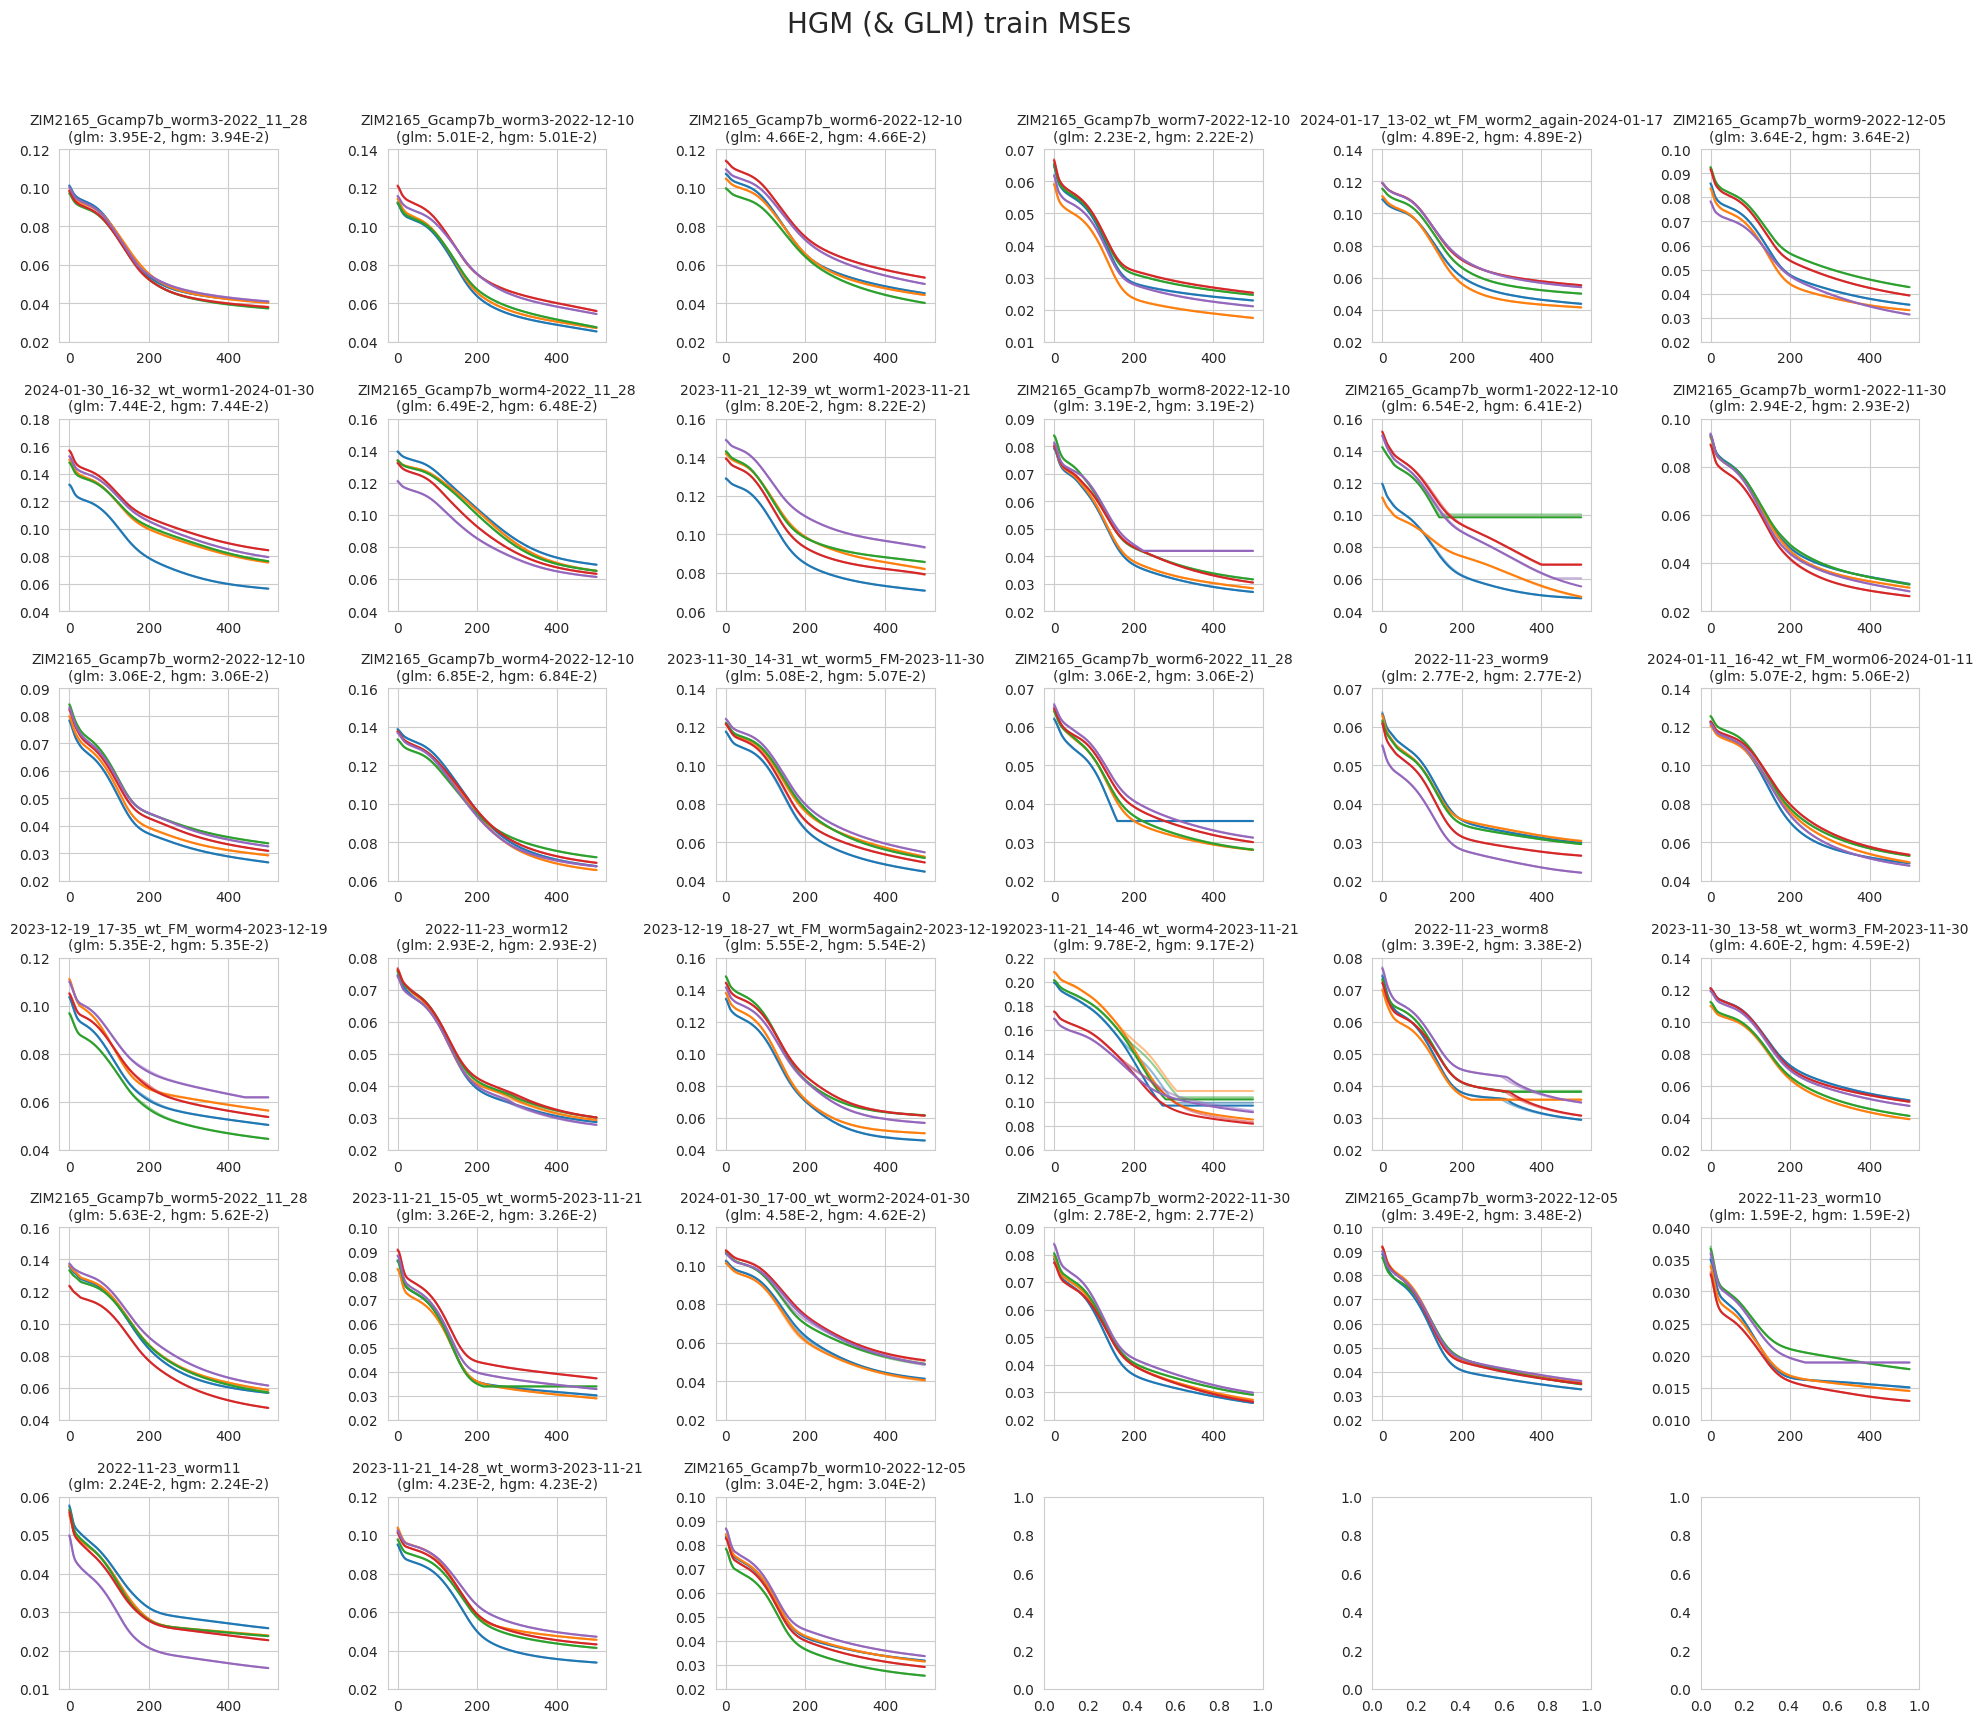

In [9]:
n_plots = 36
dim = math.ceil(math.sqrt(n_plots))
fig, axes = plt.subplots(dim, dim, figsize=(24, 20))
for i in range(n_plots):
	#axes[i // dim, i % dim].set_xticklabels([])
	#axes[i // dim, i % dim].set_yticklabels([])
	axes[i // dim, i % dim].grid(False)

for i, (losses_per_split_glm, losses_per_split_hgm) in enumerate(zip(models_t_losses_glm[:33], models_t_losses_hgm[:33])):
	colors = plt.rcParams['axes.prop_cycle'].by_key()['color']
	for j, (losses_glm, losses_hgm) in enumerate(zip(losses_per_split_glm, losses_per_split_hgm)):
		axes[i // dim, i % dim].plot(losses_glm, color=colors[j], alpha=0.5)
		axes[i // dim, i % dim].plot(losses_hgm, color=colors[j])
	axes[i // dim, i % dim].grid(True)
	axes[i // dim, i % dim].set_title(f'{filenames[i][:-14]}\n(glm: {np.average(losses_per_split_glm[:, -1], axis=0)*100:.2f}E-2, hgm: {np.average(losses_per_split_hgm[:, -1], axis=0)*100:.2f}E-2)', fontsize=10)

	yticks = axes[i // dim, i % dim].get_yticks()
	axes[i // dim, i % dim].set_yticks(yticks)
	#axes[i // dim, i % dim].set_yticklabels([f'{tick * 100:.2f}E-2' for tick in yticks])

fig.subplots_adjust(hspace=0.4, wspace=0.5)
fig.suptitle('HGM (& GLM) train MSEs', fontsize=20, y=0.95)
# plt.savefig('./out/joint-hgm-glm-train-mse')
pass

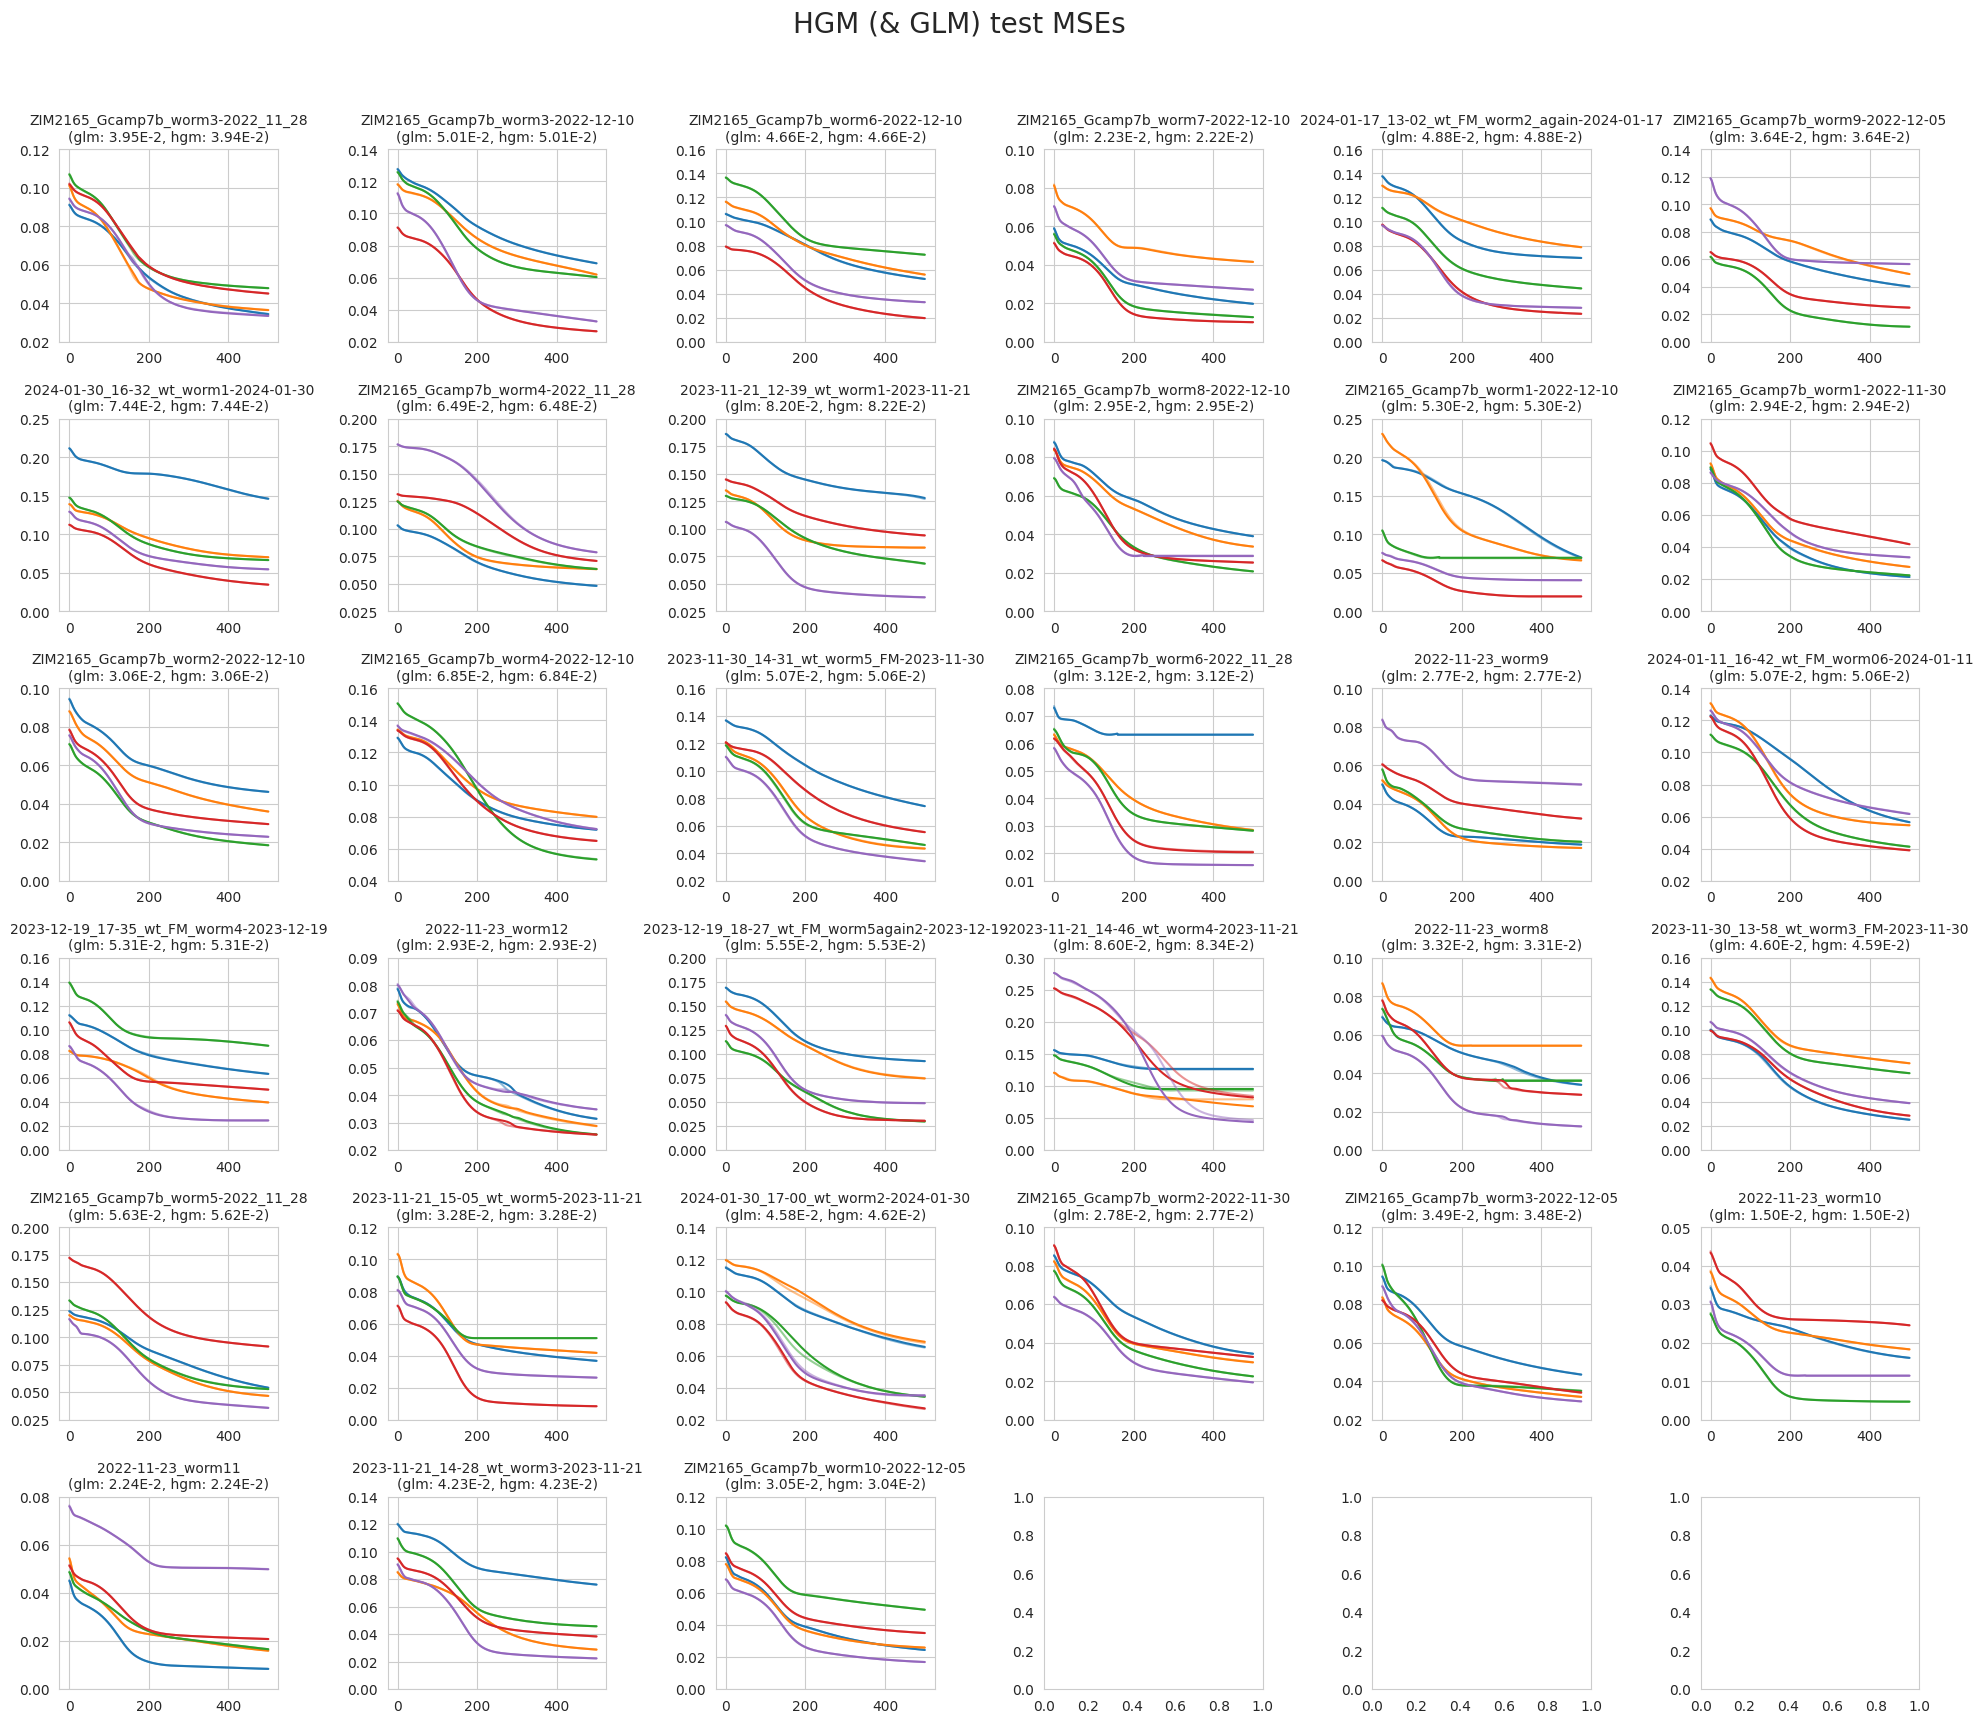

In [10]:
n_plots = 36
dim = math.ceil(math.sqrt(n_plots))
fig, axes = plt.subplots(dim, dim, figsize=(24, 20))
for i in range(n_plots):
	#axes[i // dim, i % dim].set_xticklabels([])
	#axes[i // dim, i % dim].set_yticklabels([])
	axes[i // dim, i % dim].grid(False)

for i, (losses_per_split_glm, losses_per_split_hgm) in enumerate(zip(models_losses_glm[:33], models_losses_hgm[:33])):
	colors = plt.rcParams['axes.prop_cycle'].by_key()['color']
	for j, (losses_glm, losses_hgm) in enumerate(zip(losses_per_split_glm, losses_per_split_hgm)):
		axes[i // dim, i % dim].plot(losses_glm, color=colors[j], alpha=0.5)
		axes[i // dim, i % dim].plot(losses_hgm, color=colors[j])
	axes[i // dim, i % dim].grid(True)
	axes[i // dim, i % dim].set_title(f'{filenames[i][:-14]}\n(glm: {np.average(losses_per_split_glm[:, -1], axis=0)*100:.2f}E-2, hgm: {np.average(losses_per_split_hgm[:, -1], axis=0)*100:.2f}E-2)', fontsize=10)

	yticks = axes[i // dim, i % dim].get_yticks()
	axes[i // dim, i % dim].set_yticks(yticks)
	#axes[i // dim, i % dim].set_yticklabels([f'{tick * 100:.2f}E-2' for tick in yticks])

fig.subplots_adjust(hspace=0.4, wspace=0.5)
fig.suptitle('HGM (& GLM) test MSEs', fontsize=20, y=0.95)
# plt.savefig('./out/joint-hgm-glm-test-mse')
pass

# GFP DATA

In [11]:
path = f'{os.getcwd()}/../data/{os.path.basename(os.getcwd())}/exported_data_gfp/'
gfp_hdf5files = get_hdf5_files(path)
gfp_filenames = [get_filename(file) for file in gfp_hdf5files]
gfp_continuous_behaviors = [get_continuous_behaviors(file) for file in gfp_hdf5files]
gfp_discrete_states = [get_discrete_states(file) for file in gfp_hdf5files]
gfp_eigenworms = [get_eigenworms(file) for file in gfp_hdf5files]
gfp_kymographs = [get_kymograph(file) for file in gfp_hdf5files]
gfp_traces = [get_neuronal_traces(file) for file in gfp_hdf5files]

### preprocessing

In [12]:
for i in range(len(gfp_filenames)):
	mask = gfp_eigenworms[i].notna().all(axis=1)
	#continuous_behaviors[i] = continuous_behaviors[i][mask]
	gfp_discrete_states[i] = gfp_discrete_states[i][mask]
	gfp_eigenworms[i] = gfp_eigenworms[i][mask]
	gfp_traces[i] = gfp_traces[i][mask]

	#gfp_kymographs[i] = gfp_kymographs[i][mask]
	#gfp_filenames[i] = gfp_filenames[i][mask]

### HGM

In [13]:
selection = ['REV', 'VENTRAL_TURN', 'DORSAL_TURN', 'PAUSE']

random_key = jax.random.PRNGKey(0)
optimizer = optax.adam(1e-3)

max_epochs = 500
min_epochs = 10
max_patience = 20

gfp_models_params_hgm = list()
gfp_models_losses_hgm = list()
gfp_models_t_losses_hgm = list()
gfp_models_scores_hgm = list()
gfp_models_epochs_hgm = list()
for i in range(len(gfp_filenames)):
	print(f'{i+1}/{len(gfp_filenames)}: {gfp_filenames[i]}  ', end='')

	X = gfp_traces[i].values
	B_hl = gfp_discrete_states[i][selection].values
	B_ll = gfp_eigenworms[i].values

	n_neurons = X.shape[1]
	n_dimensions = 2
	n_behaviors_hl = B_hl.shape[1]
	n_behaviors_ll = B_ll.shape[1]


	cv = StratifiedKFold(n_splits=5)
	splits = list(cv.split(np.zeros(gfp_traces[i].shape[0]), gfp_discrete_states[i]['REV'].values))

	losses_per_split = list()
	t_losses_per_split = list()
	scores_per_split = list()
	epochs_per_split = list()
	for train, test in splits:
		X_train, X_test = X[train], X[test]
		B_hl_train, B_hl_test = B_hl[train], B_hl[test]
		B_ll_train, B_ll_test = B_ll[train], B_ll[test]

		params = init_params_hgm((n_neurons, n_dimensions), (n_dimensions, n_behaviors_hl), (n_behaviors_ll, n_neurons), (n_dimensions, n_neurons))
		opt_state = optimizer.init(params)

		best_params = params
		best_loss = 1.1

		patience = 0
		losses = [loss_fn_hgm(params, X_test, B_ll_test, B_hl_test).item()]
		t_losses = [loss_fn_hgm(params, X_train, B_ll_train, B_hl_train).item()]
		for epoch in range(max_epochs):
			params, opt_state = update_hgm(opt_state, params, X, B_ll, B_hl)
			loss = loss_fn_hgm(params, X_test, B_ll_test, B_hl_test).item()
			t_loss = loss_fn_hgm(params, X_train, B_ll_train, B_hl_train).item()

			# early stopping =============
			if epoch > min_epochs:
				if loss < best_loss:
					losses.append(loss)
					t_losses.append(t_loss)
					best_loss = loss
					best_params = params
					patience = 0
				else:
					patience += 1
					if patience > max_patience:
						losses_padding = [best_loss for _ in range(max_epochs - len(losses) + 1)]
						t_losses_padding = [t_losses[-1] for _ in range(max_epochs - len(t_losses) + 1)]
						losses = losses + losses_padding
						t_losses = t_losses + t_losses_padding
						epochs_per_split.append(epoch + 1)
						break
					losses.append(loss)
					t_losses.append(t_loss)
			# ============================
			else:
				losses.append(loss)
				t_losses.append(t_loss)
		losses_per_split.append(losses)
		t_losses_per_split.append(t_losses)

		U = params['U']
		X_man = X_test @ U
		X_rec = X_man @ jax.numpy.linalg.pinv(U)
		X_res = X_test - X_rec
		Y_pred = predict_hgm(X_test, B_ll_test, params)
		score_per_neuron = [r2_score(trace, trace_pred) for trace, trace_pred in zip(X_res.T, Y_pred.T)]
		scores_per_split.append(score_per_neuron)

		if len(epochs_per_split) == 0:
			epochs_per_split.append(max_epochs)

	gfp_models_t_losses_hgm.append(np.array(t_losses_per_split))
	gfp_models_losses_hgm.append(np.array(losses_per_split))

	scores_per_split_avg = np.array(scores_per_split).mean(axis=0)
	gfp_models_scores_hgm.append(scores_per_split_avg)

	epochs_per_split_avg = np.array(epochs_per_split).mean()
	gfp_models_epochs_hgm.append(epochs_per_split_avg)

1/8: ZIM2319_GFP_worm3-2022-12-10_no_image_data  2/8: ZIM2319_GFP_worm1-2022-12-10_no_image_data  3/8: ZIM2319_GFP_worm2-2022-12-10_no_image_data  4/8: ZIM2319_GFP_worm6-2022-12-10_no_image_data  5/8: ZIM2319_GFP_worm8-2022-12-10_no_image_data  6/8: ZIM2319_GFP_worm4-2022-12-10_no_image_data  7/8: ZIM2319_GFP_worm7-2022-12-10_no_image_data  8/8: ZIM2319_GFP_worm5-2022-12-10_no_image_data  

### GLM

In [14]:
selection = ['REV', 'VENTRAL_TURN', 'DORSAL_TURN', 'PAUSE']

random_key = jax.random.PRNGKey(0)
optimizer = optax.adam(1e-3)

max_epochs = 500
min_epochs = 10
max_patience = 20

gfp_models_params_glm = list()
gfp_models_losses_glm = list()
gfp_models_t_losses_glm = list()
gfp_models_scores_glm = list()
gfp_models_epochs_glm = list()
for i in range(len(gfp_filenames)):
	print(f'{i+1}/{len(gfp_filenames)}: {gfp_filenames[i]}  ', end='')

	X = gfp_traces[i].values
	B_hl = gfp_discrete_states[i][selection].values
	B_ll = gfp_eigenworms[i].values

	n_neurons = X.shape[1]
	n_dimensions = 2
	n_behaviors_hl = B_hl.shape[1]
	n_behaviors_ll = B_ll.shape[1]


	cv = StratifiedKFold(n_splits=5)
	splits = list(cv.split(np.zeros(gfp_traces[i].shape[0]), gfp_discrete_states[i]['REV'].values))

	losses_per_split = list()
	t_losses_per_split = list()
	scores_per_split = list()
	epochs_per_split = list()
	for train, test in splits:
		X_train, X_test = X[train], X[test]
		B_hl_train, B_hl_test = B_hl[train], B_hl[test]
		B_ll_train, B_ll_test = B_ll[train], B_ll[test]

		params = init_params_glm((n_neurons, n_dimensions), (n_dimensions, n_behaviors_hl), (n_behaviors_ll, n_neurons))
		opt_state = optimizer.init(params)

		best_params = params
		best_loss = 1.1

		patience = 0
		losses = [loss_fn_glm(params, X_test, B_ll_test, B_hl_test).item()]
		t_losses = [loss_fn_glm(params, X_train, B_ll_train, B_hl_train).item()]
		for epoch in range(max_epochs):
			params, opt_state = update_glm(opt_state, params, X, B_ll, B_hl)
			loss = loss_fn_glm(params, X_test, B_ll_test, B_hl_test).item()
			t_loss = loss_fn_glm(params, X_train, B_ll_train, B_hl_train).item()

			# early stopping =============
			if epoch > min_epochs:
				if loss < best_loss:
					losses.append(loss)
					t_losses.append(t_loss)
					best_loss = loss
					best_params = params
					patience = 0
				else:
					patience += 1
					if patience > max_patience:
						losses_padding = [best_loss for _ in range(max_epochs - len(losses) + 1)]
						t_losses_padding = [t_losses[-1] for _ in range(max_epochs - len(t_losses) + 1)]
						losses = losses + losses_padding
						t_losses = t_losses + t_losses_padding
						epochs_per_split.append(epoch + 1)
						break
					losses.append(loss)
					t_losses.append(t_loss)
			# ============================
			else:
				losses.append(loss)
				t_losses.append(t_loss)
		losses_per_split.append(losses)
		t_losses_per_split.append(t_losses)

		U = params['U']
		X_man = X_test @ U
		X_rec = X_man @ jax.numpy.linalg.pinv(U)
		X_res = X_test - X_rec
		Y_pred = predict_glm(B_ll_test, params)
		score_per_neuron = [r2_score(trace, trace_pred) for trace, trace_pred in zip(X_res.T, Y_pred.T)]
		scores_per_split.append(score_per_neuron)

		if len(epochs_per_split) == 0:
			epochs_per_split.append(max_epochs)

	gfp_models_t_losses_glm.append(np.array(t_losses_per_split))
	gfp_models_losses_glm.append(np.array(losses_per_split))

	scores_per_split_avg = np.array(scores_per_split).mean(axis=0)
	gfp_models_scores_glm.append(scores_per_split_avg)

	epochs_per_split_avg = np.array(epochs_per_split).mean()
	gfp_models_epochs_glm.append(epochs_per_split_avg)

1/8: ZIM2319_GFP_worm3-2022-12-10_no_image_data  2/8: ZIM2319_GFP_worm1-2022-12-10_no_image_data  3/8: ZIM2319_GFP_worm2-2022-12-10_no_image_data  4/8: ZIM2319_GFP_worm6-2022-12-10_no_image_data  5/8: ZIM2319_GFP_worm8-2022-12-10_no_image_data  6/8: ZIM2319_GFP_worm4-2022-12-10_no_image_data  7/8: ZIM2319_GFP_worm7-2022-12-10_no_image_data  8/8: ZIM2319_GFP_worm5-2022-12-10_no_image_data  

### plots

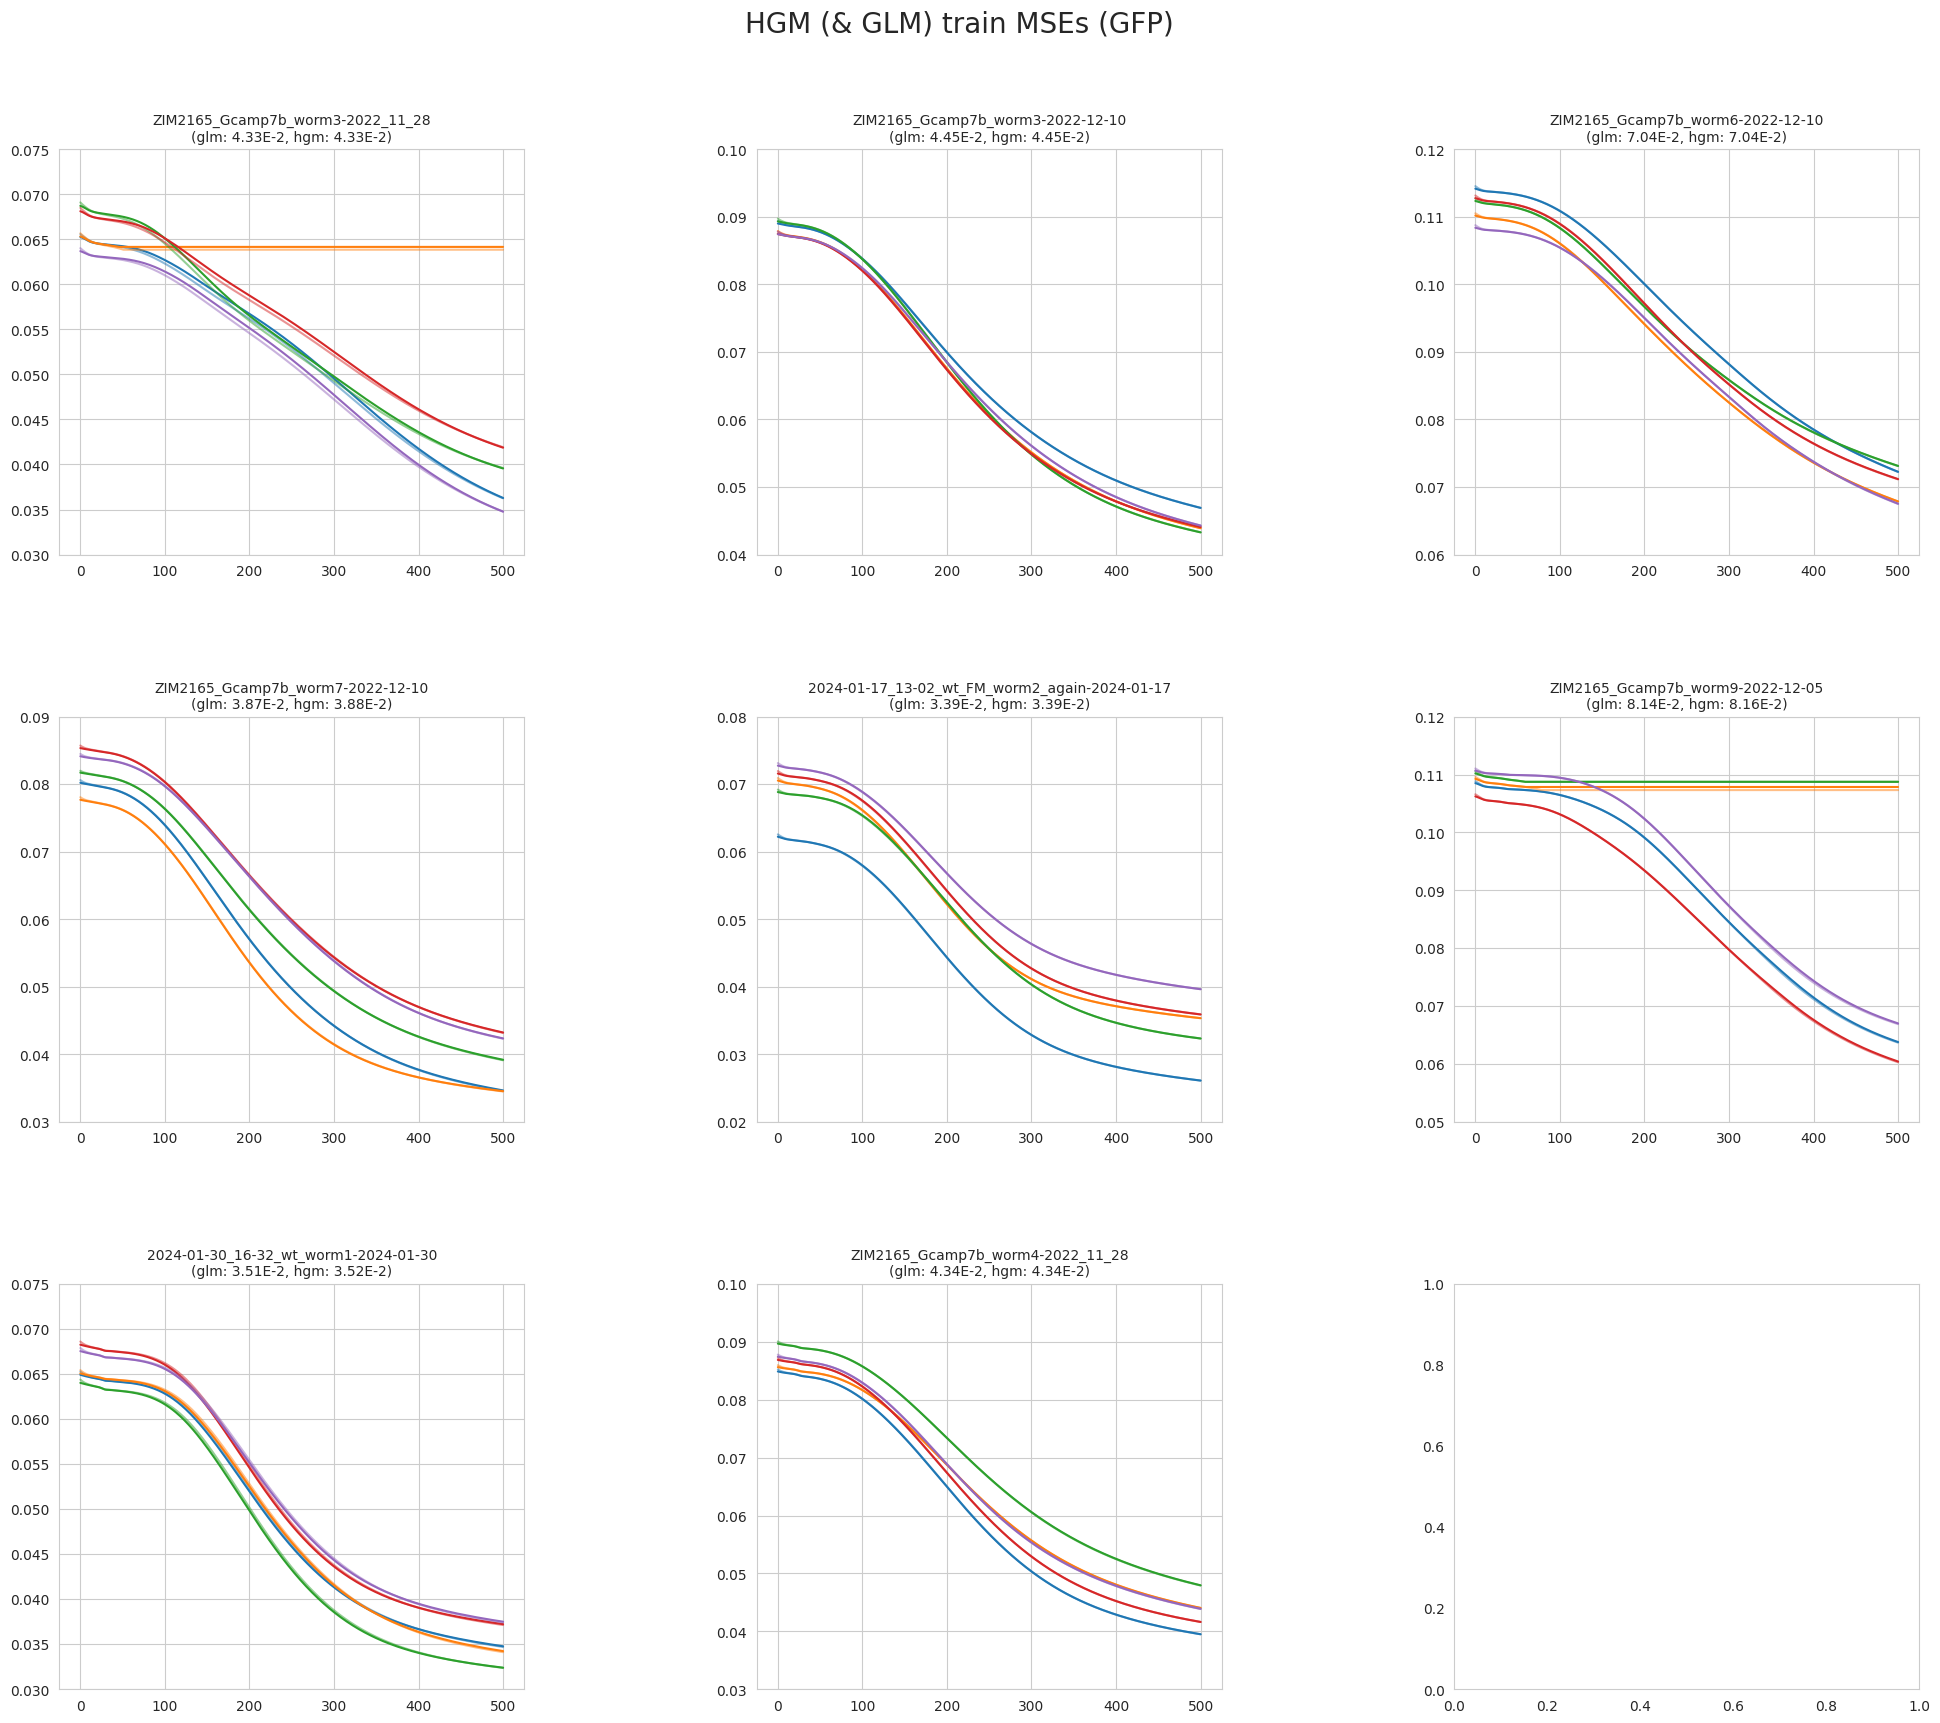

In [15]:
n_plots = 9
dim = math.ceil(math.sqrt(n_plots))
fig, axes = plt.subplots(dim, dim, figsize=(24, 20))
for i in range(n_plots):
	#axes[i // dim, i % dim].set_xticklabels([])
	#axes[i // dim, i % dim].set_yticklabels([])
	axes[i // dim, i % dim].grid(False)

for i, (losses_per_split_glm, losses_per_split_hgm) in enumerate(zip(gfp_models_t_losses_glm[:8], gfp_models_t_losses_hgm[:8])):
	colors = plt.rcParams['axes.prop_cycle'].by_key()['color']
	for j, (losses_glm, losses_hgm) in enumerate(zip(losses_per_split_glm, losses_per_split_hgm)):
		axes[i // dim, i % dim].plot(losses_glm, color=colors[j], alpha=0.5)
		axes[i // dim, i % dim].plot(losses_hgm, color=colors[j])
	axes[i // dim, i % dim].grid(True)
	axes[i // dim, i % dim].set_title(f'{filenames[i][:-14]}\n(glm: {np.average(losses_per_split_glm[:, -1], axis=0)*100:.2f}E-2, hgm: {np.average(losses_per_split_hgm[:, -1], axis=0)*100:.2f}E-2)', fontsize=10)

	yticks = axes[i // dim, i % dim].get_yticks()
	axes[i // dim, i % dim].set_yticks(yticks)
	#axes[i // dim, i % dim].set_yticklabels([f'{tick * 100:.2f}E-2' for tick in yticks])

fig.subplots_adjust(hspace=0.4, wspace=0.5)
fig.suptitle('HGM (& GLM) train MSEs (GFP)', fontsize=20, y=0.95)
# plt.savefig('./out/joint-hgm-glm-train-mse-gfp')
pass

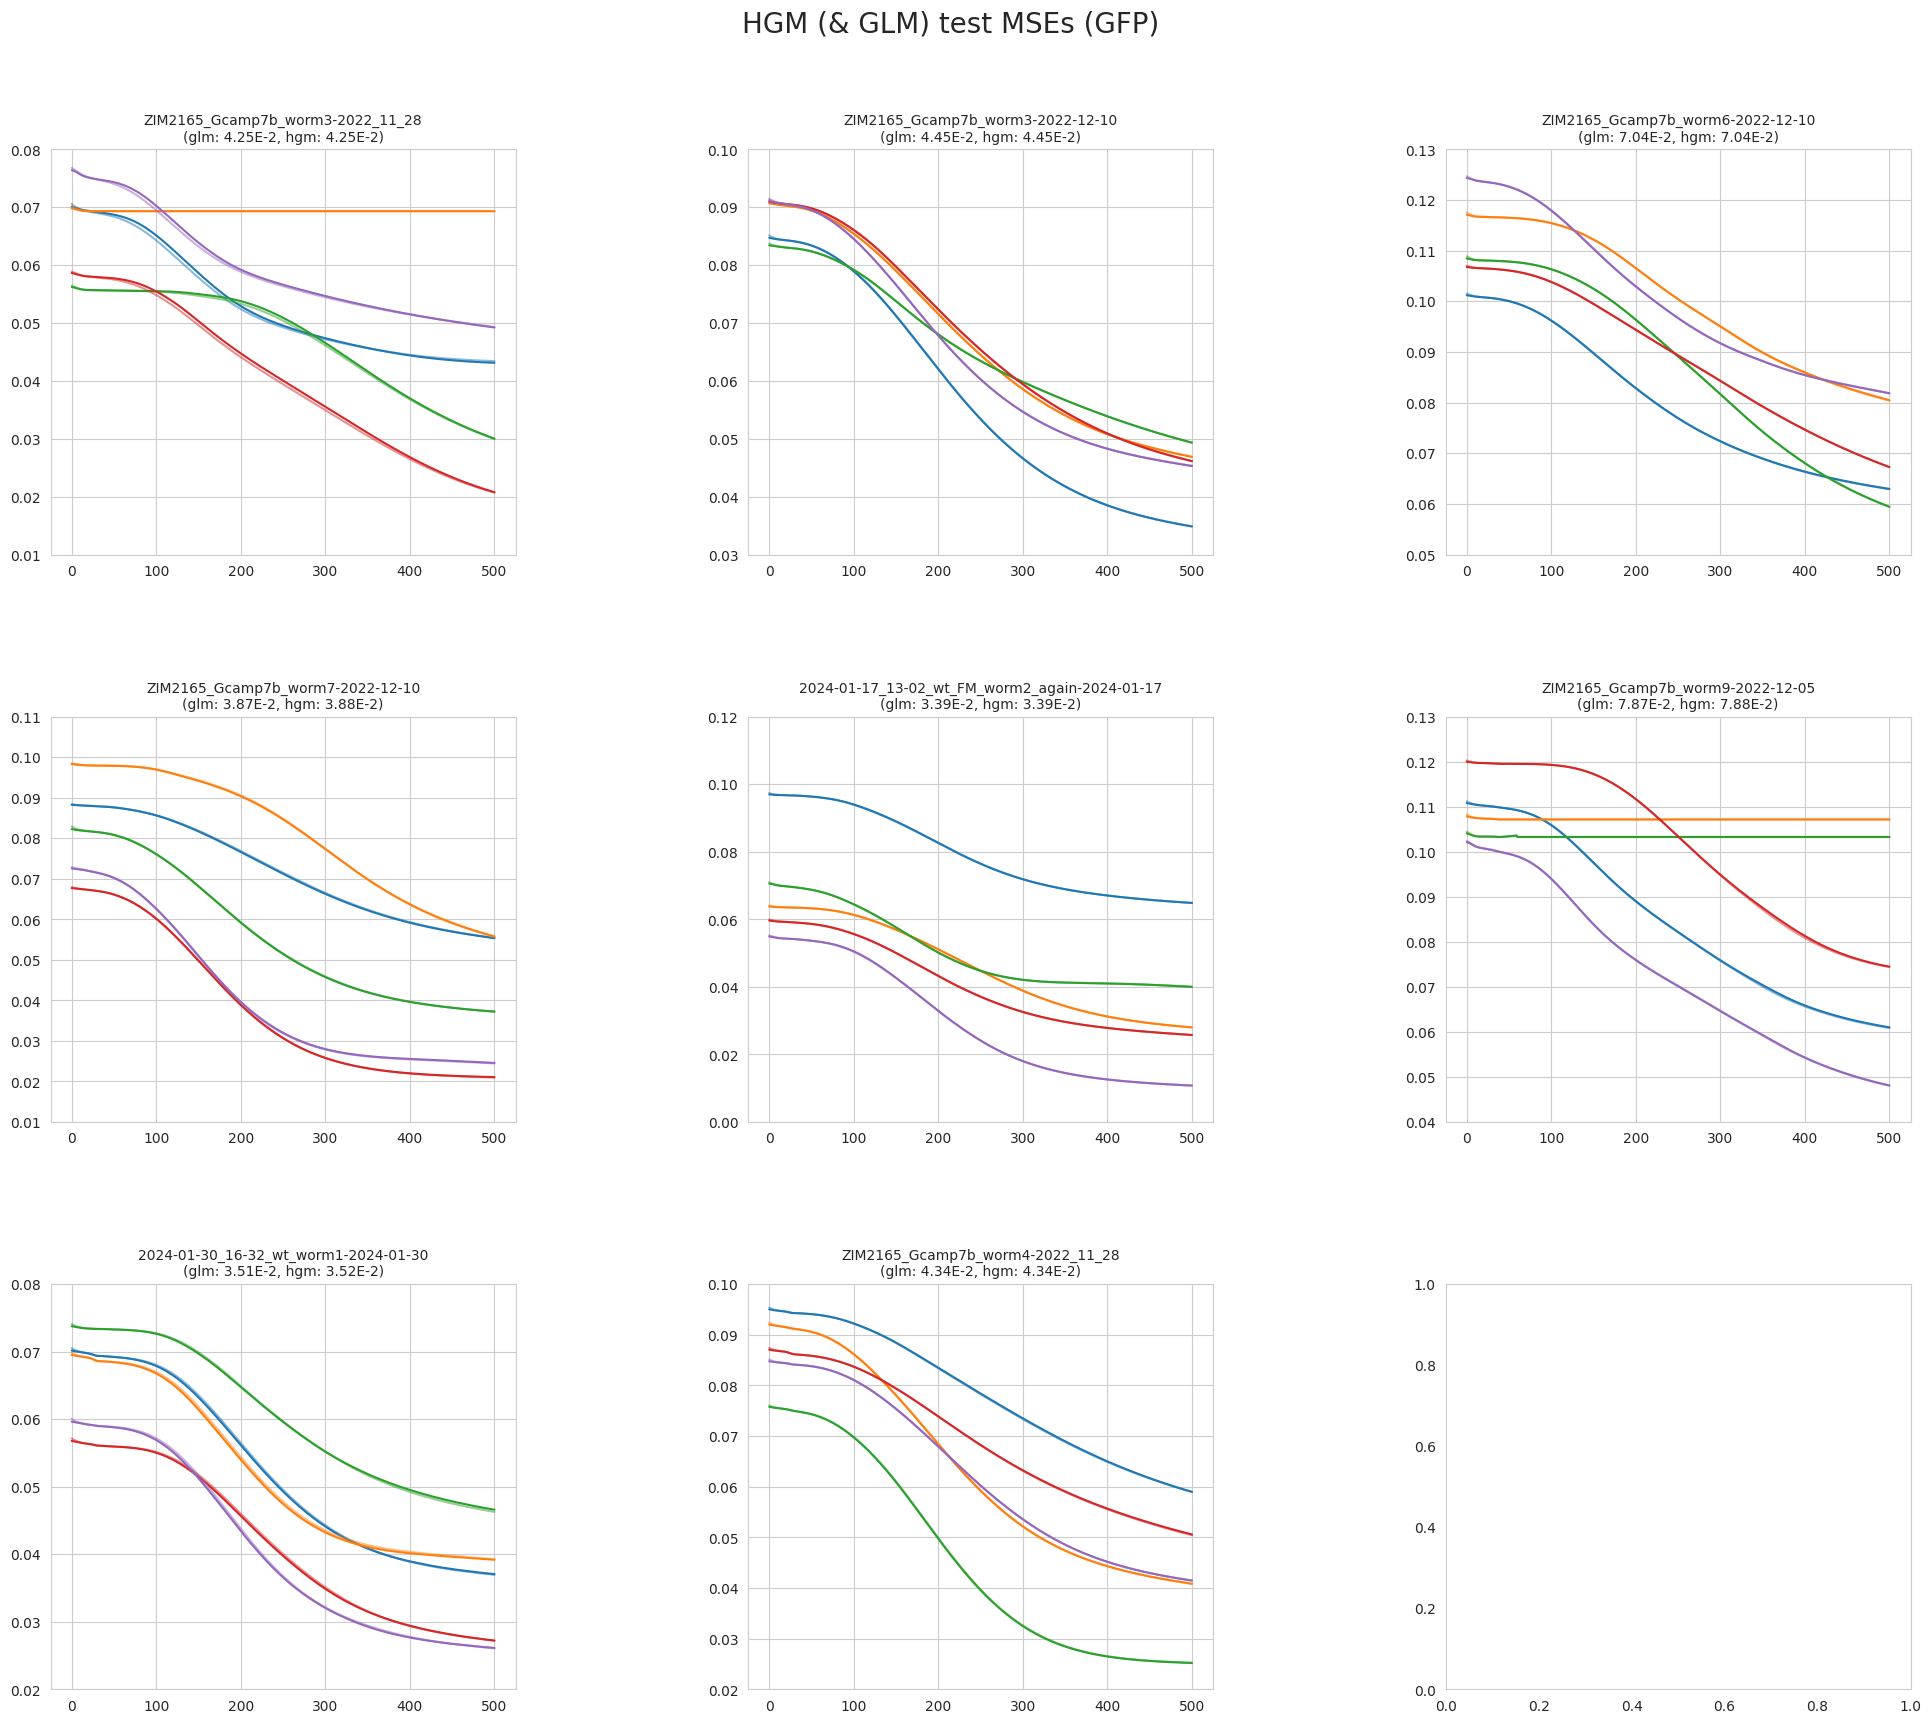

In [16]:
n_plots = 9
dim = math.ceil(math.sqrt(n_plots))
fig, axes = plt.subplots(dim, dim, figsize=(24, 20))
for i in range(n_plots):
	#axes[i // dim, i % dim].set_xticklabels([])
	#axes[i // dim, i % dim].set_yticklabels([])
	axes[i // dim, i % dim].grid(False)

for i, (losses_per_split_glm, losses_per_split_hgm) in enumerate(zip(gfp_models_losses_glm[:8], gfp_models_losses_hgm[:8])):
	colors = plt.rcParams['axes.prop_cycle'].by_key()['color']
	for j, (losses_glm, losses_hgm) in enumerate(zip(losses_per_split_glm, losses_per_split_hgm)):
		axes[i // dim, i % dim].plot(losses_glm, color=colors[j], alpha=0.5)
		axes[i // dim, i % dim].plot(losses_hgm, color=colors[j])
	axes[i // dim, i % dim].grid(True)
	axes[i // dim, i % dim].set_title(f'{filenames[i][:-14]}\n(glm: {np.average(losses_per_split_glm[:, -1], axis=0)*100:.2f}E-2, hgm: {np.average(losses_per_split_hgm[:, -1], axis=0)*100:.2f}E-2)', fontsize=10)

	yticks = axes[i // dim, i % dim].get_yticks()
	axes[i // dim, i % dim].set_yticks(yticks)
	#axes[i // dim, i % dim].set_yticklabels([f'{tick * 100:.2f}E-2' for tick in yticks])

fig.subplots_adjust(hspace=0.4, wspace=0.5)
fig.suptitle('HGM (& GLM) test MSEs (GFP)', fontsize=20, y=0.95)
# plt.savefig('./out/joint-hgm-glm-test-mse-gfp')
pass

# assemble

In [17]:
neurons_labels = [traces[i].columns for i in range(len(filenames))]

unique_labels = sorted(list(set([l for label in neurons_labels for l in label])))
unique_labels_filtered = [label for label in unique_labels if label != '' and label[-1] != '_']

neuron_scores = dict()
for label_list, score_glm_list, score_hgm_list in zip(neurons_labels, models_scores_glm, models_scores_hgm):
	for i in range(len(label_list)):
		label = label_list[i]
		if label != '' and label[-1] != '_':
			score_glm_new, score_hgm_new = np.array(score_glm_list[i]), np.array(score_hgm_list[i])
			if len(score_hgm_new.shape) == 0:
				score_glm_new = score_glm_new.reshape(1, 1)
				score_hgm_new = score_hgm_new.reshape(1, 1)
			if label not in neuron_scores.keys():
				neuron_scores[label] = (score_glm_new, score_hgm_new)
			else:
				score_glm_prev, score_hgm_prev = neuron_scores[label]
				neuron_scores[label] = (np.vstack([score_glm_prev, score_glm_new]), np.vstack([score_hgm_prev, score_hgm_new]))

In [18]:
gfp_neurons_labels = [gfp_traces[i].columns for i in range(len(gfp_filenames))]

gfp_unique_labels = sorted(list(set([l for label in gfp_neurons_labels for l in label])))
gfp_unique_labels_filtered = [label for label in gfp_unique_labels if label != '' and label[-1] != '_']

gfp_neuron_scores = dict()
for label_list, score_glm_list, score_hgm_list in zip(gfp_neurons_labels, gfp_models_scores_glm, gfp_models_scores_hgm):
	for i in range(len(label_list)):
		label = label_list[i]
		if label != '' and label[-1] != '_':
			score_glm_new, score_hgm_new = np.array(score_glm_list[i]), np.array(score_hgm_list[i])
			if len(score_hgm_new.shape) == 0:
				score_glm_new = score_glm_new.reshape(1, 1)
				score_hgm_new = score_hgm_new.reshape(1, 1)
			if label not in gfp_neuron_scores.keys():
				gfp_neuron_scores[label] = (score_glm_new, score_hgm_new)
			else:
				score_glm_prev, score_hgm_prev = gfp_neuron_scores[label]
				gfp_neuron_scores[label] = (np.vstack([score_glm_prev, score_glm_new]), np.vstack([score_hgm_prev, score_hgm_new]))

# Plots

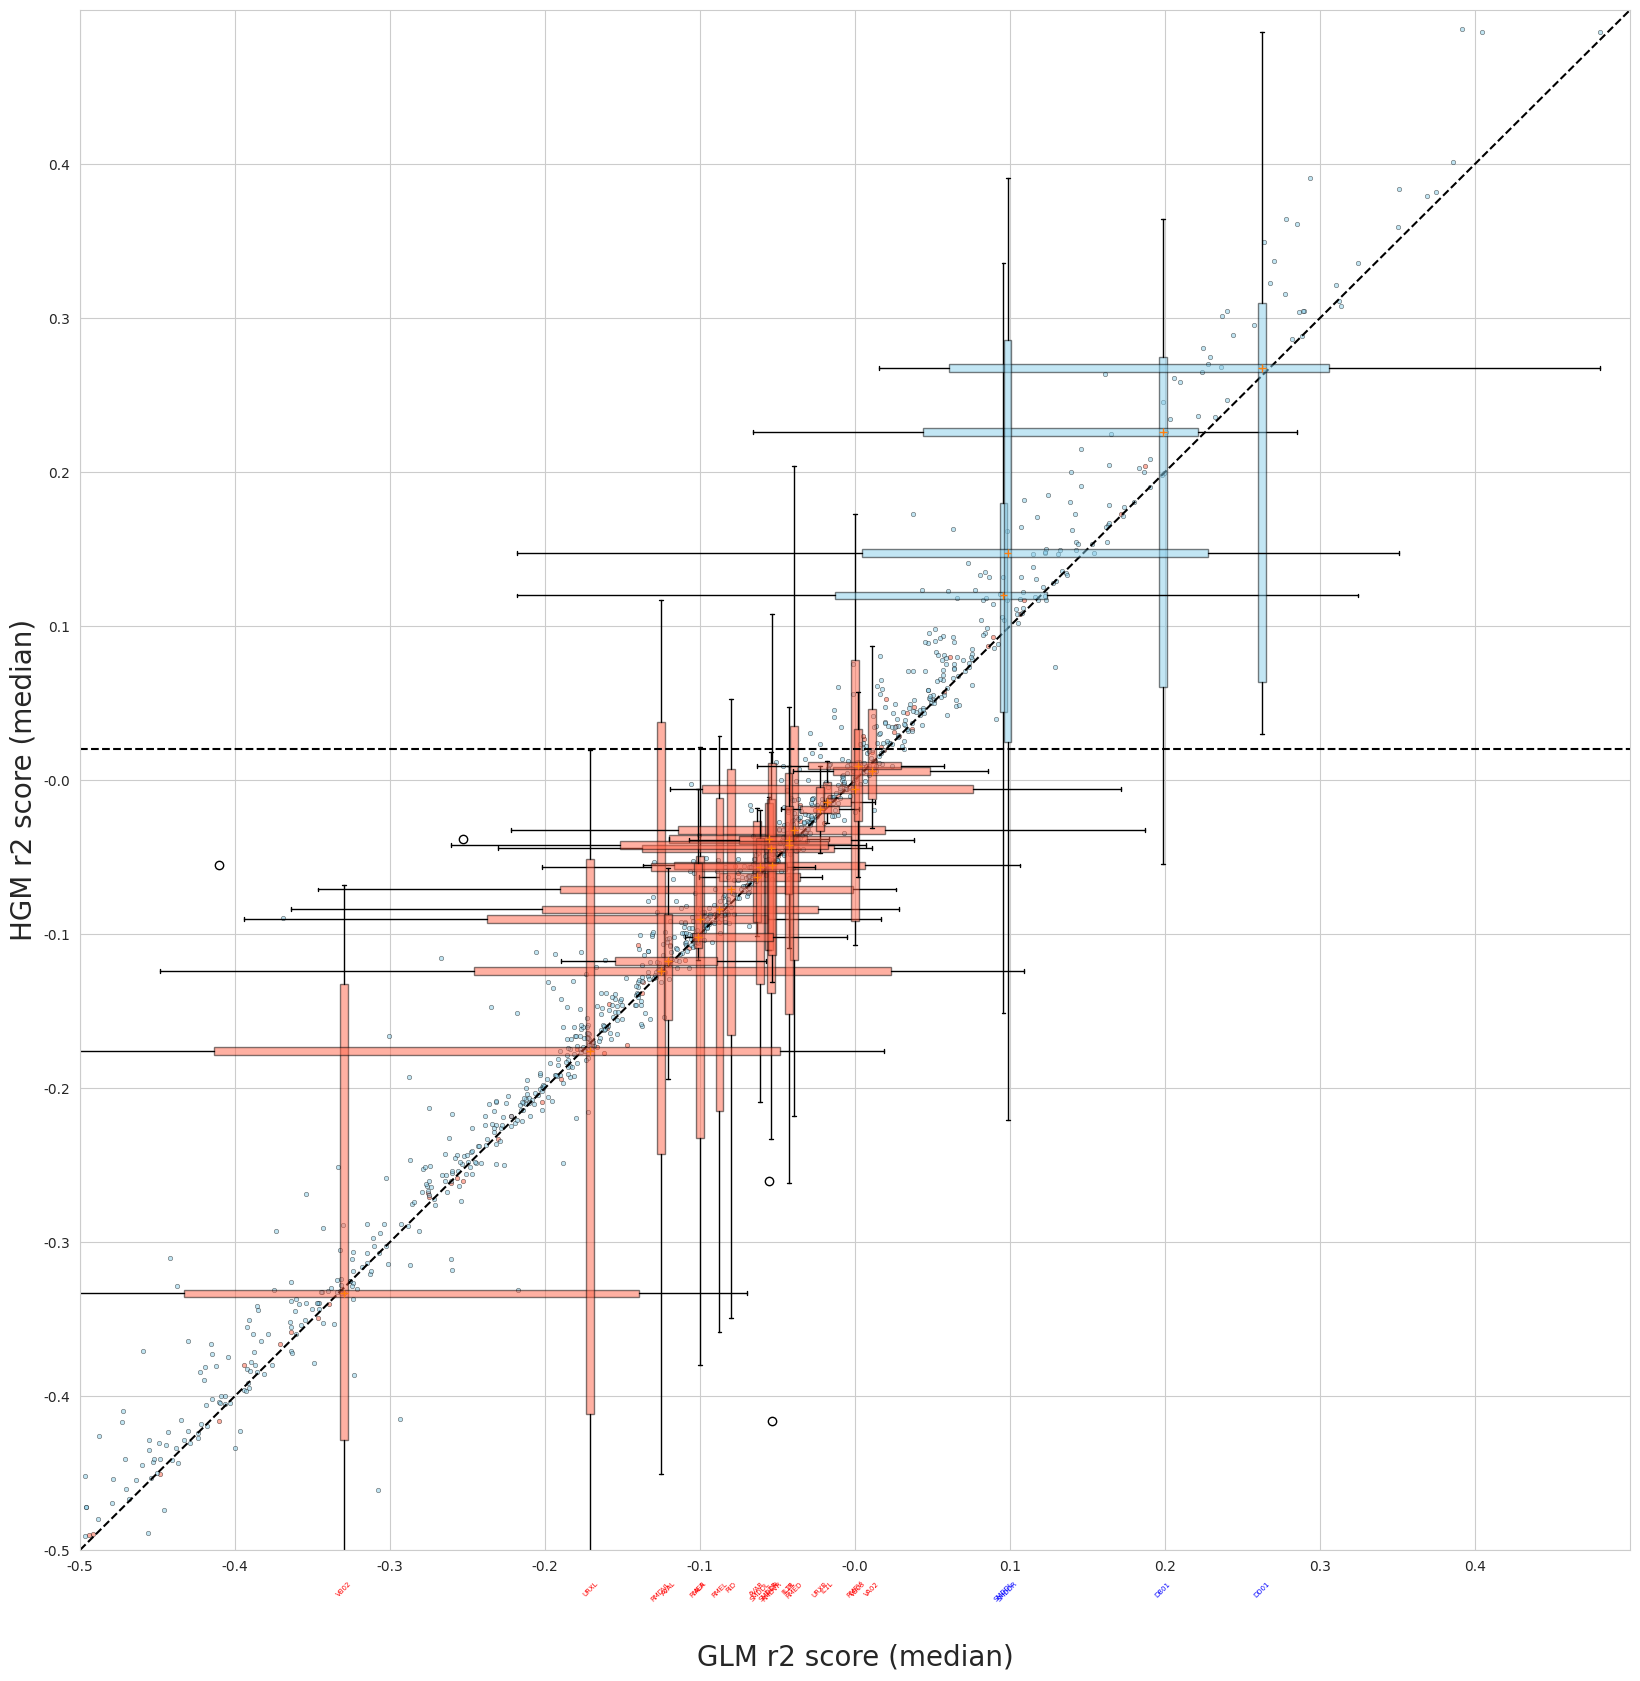

In [19]:
threshold = 0.95

plt.figure(figsize=(20, 20))
plt.xlabel('GLM r2 score (median)', fontsize=20, labelpad=50)
plt.ylabel('HGM r2 score (median)', fontsize=20)

max_x = 0.5
max_y = 0.5
plt.xlim(-max_x, max_x)
plt.ylim(-max_y, max_y)

plt.plot([-max_x, max_x + 1], [-max_y, max_y + 1], color='black', linestyle='--')


# GFP =============================================================================================================
gfp_boxplot_xticks, gfp_boxplot_xtick_labels = list(), list()

keys = gfp_neuron_scores.keys()
for key in keys:
	scores_glm, scores_hgm = gfp_neuron_scores[key]
	if len(scores_hgm.shape) == 0:
		scores_glm = scores_glm.reshape(1, 1)
		scores_hgm = scores_hgm.reshape(1, 1)

	plt.scatter(scores_glm, scores_hgm, s=10, c='tomato', edgecolor='black', linewidth=0.5, alpha=0.5)

	x = np.median(scores_glm)
	y = np.median(scores_hgm)

	gfp_boxplot_xticks.append(x)
	gfp_boxplot_xtick_labels.append(f'{key}')

	boxplot_h = plt.boxplot(scores_hgm, positions=[x], widths=0.005 * max_x / max_y, patch_artist=True, showfliers=True)
	boxplot_v = plt.boxplot(scores_glm, positions=[y], widths=0.005 * max_y / max_x, patch_artist=True, showfliers=True, vert=False)
	for box in [boxplot_h, boxplot_v]:
		for patch in box['boxes']:
			patch.set_facecolor('tomato')
			patch.set_alpha(0.5)

for x, label in zip(gfp_boxplot_xticks, gfp_boxplot_xtick_labels):
	plt.text(x, -max_y-0.02, label, color='red', ha='center', va='top', rotation=45, fontsize=5, transform=plt.gca().transData)
# =================================================================================================================


gfp_high_score_hgm_impr = np.quantile(np.concatenate([pair[1] - pair[0] for pair in gfp_neuron_scores.values()]), threshold)
gfp_high_score_glm = np.quantile(np.concatenate([pair[0] for pair in gfp_neuron_scores.values()]), threshold)
gfp_high_score_hgm = np.quantile(np.concatenate([pair[1] for pair in gfp_neuron_scores.values()]), threshold)
plt.plot([-max_x, max_x + 1], [gfp_high_score_hgm_impr, gfp_high_score_hgm_impr], color='black', linestyle='--')


# GCAMP ===========================================================================================================
boxplot_xticks, boxplot_xtick_labels = list(), list()

keys = neuron_scores.keys()
for key in keys:
	scores_glm, scores_hgm = neuron_scores[key]
	if len(scores_hgm.shape) == 0:
		scores_glm = scores_glm.reshape(1, 1)
		scores_hgm = scores_hgm.reshape(1, 1)

	plt.scatter(scores_glm, scores_hgm, s=10, c='skyblue', edgecolor='black', linewidth=0.5, alpha=0.5)

	x = np.median(scores_glm)
	# if x < gfp_high_score_glm: continue
	y = np.median(scores_hgm)
	if y < gfp_high_score_hgm: continue

	boxplot_xticks.append(x)
	boxplot_xtick_labels.append(f'{key}')

	boxplot_h = plt.boxplot(scores_hgm, positions=[x], widths=0.005 * max_x / max_y, patch_artist=True, showfliers=True)
	boxplot_v = plt.boxplot(scores_glm, positions=[y], widths=0.005 * max_y / max_x, patch_artist=True, showfliers=True, vert=False)
	for box in [boxplot_h, boxplot_v]:
		for patch in box['boxes']:
			patch.set_facecolor('skyblue')
			patch.set_alpha(0.5)

for x, label in zip(boxplot_xticks, boxplot_xtick_labels):
	plt.text(x, -max_y-0.02, label, color='blue', ha='center', va='top', rotation=45, fontsize=5, transform=plt.gca().transData)
# =================================================================================================================


plt.xticks(np.arange(-max_x, max_x, 0.1), [f'{val:.1f}' for val in np.arange(-max_x, max_x, 0.1)])
plt.yticks(np.arange(-max_y, max_y, 0.1), [f'{val:.1f}' for val in np.arange(-max_y, max_y, 0.1)])

plt.savefig('out/joint-hgm-vs-glm-scores', dpi=300)

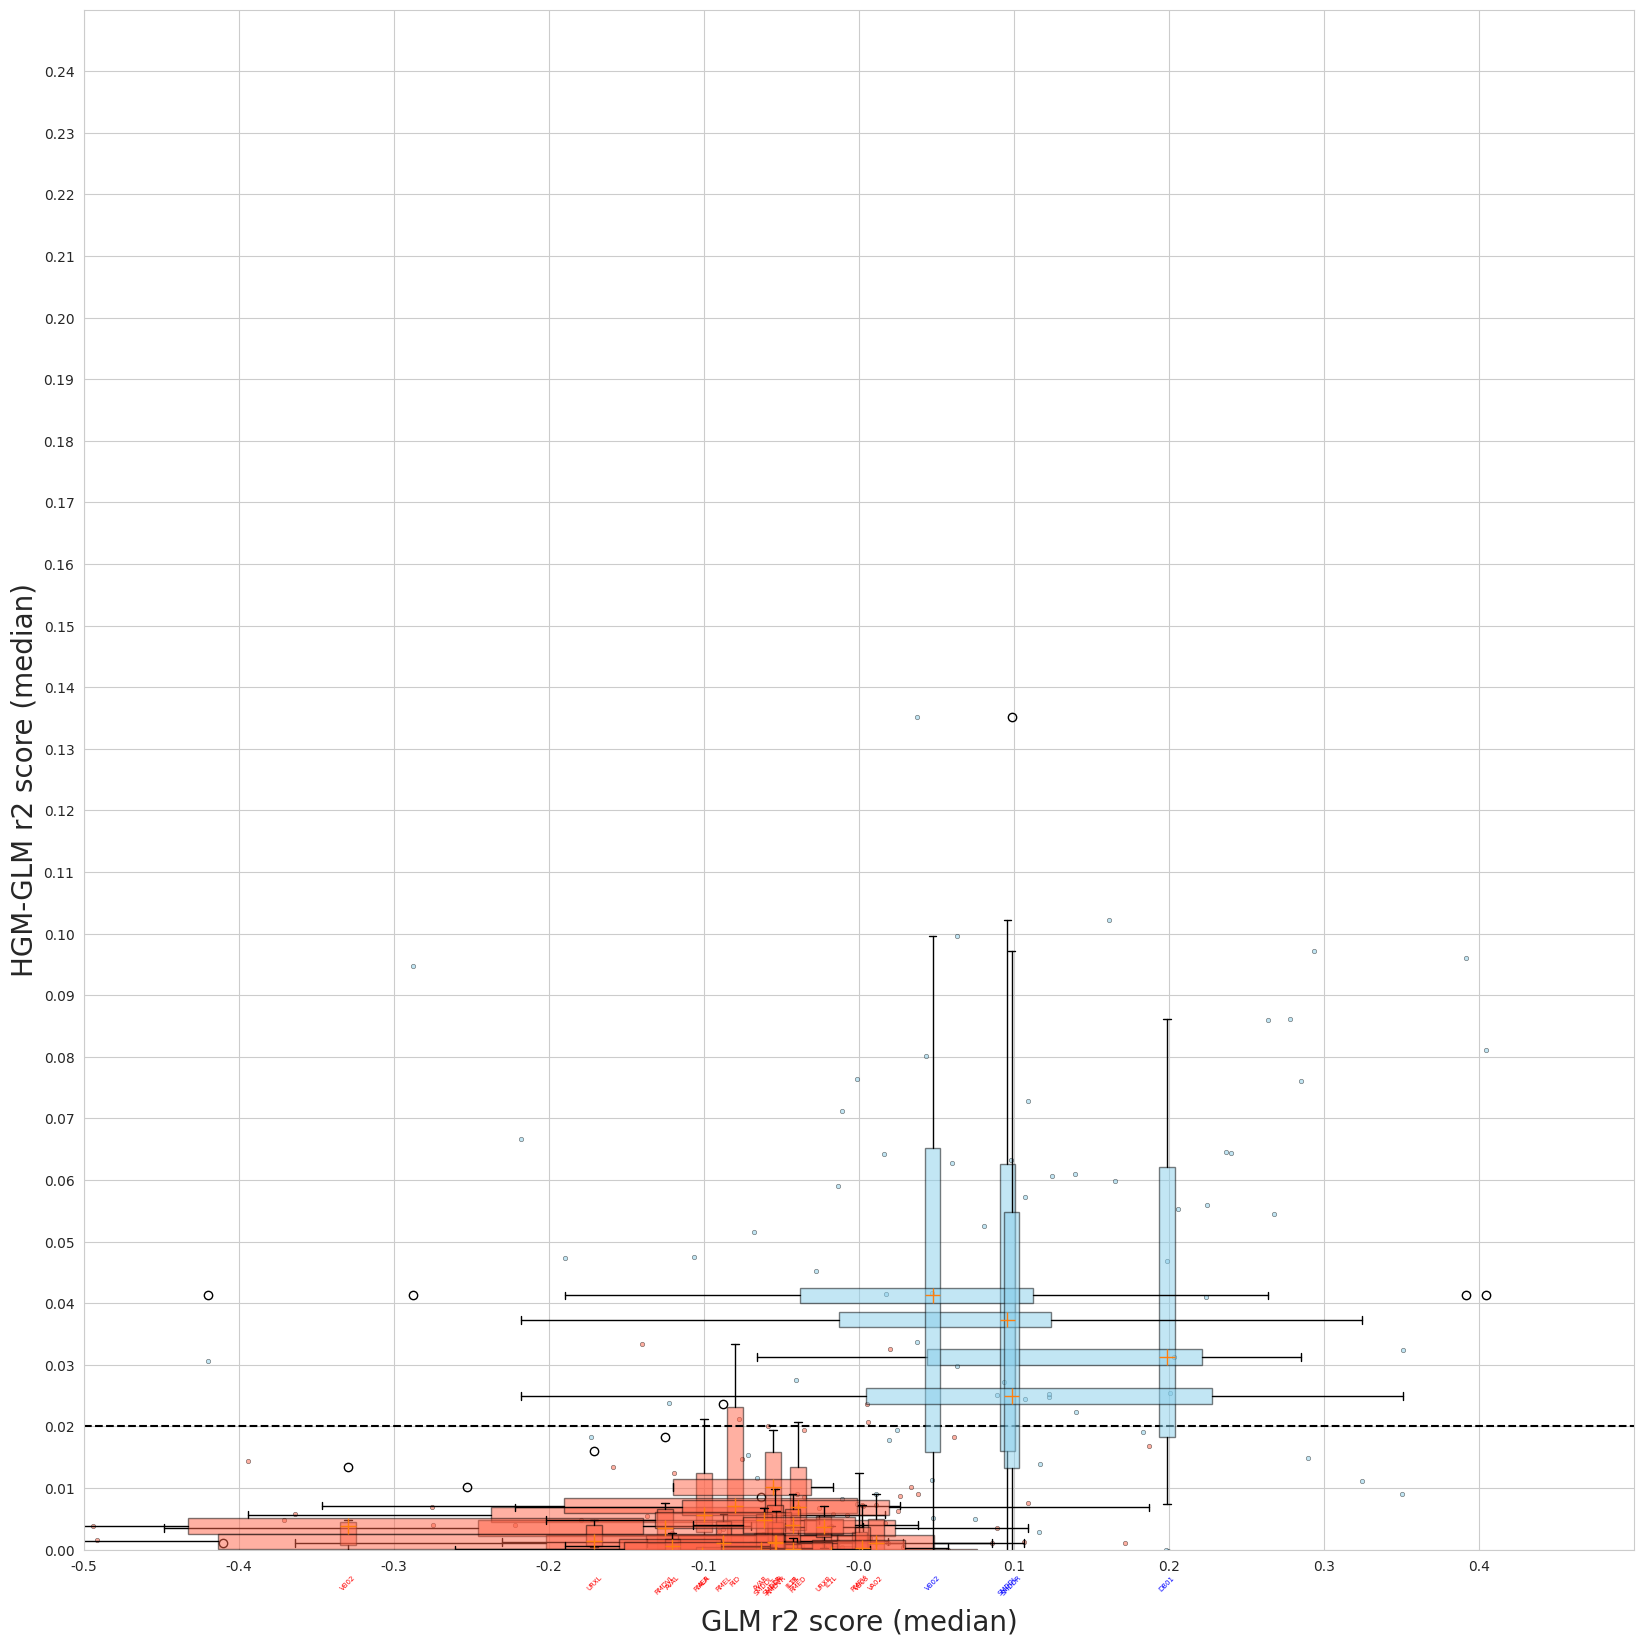

In [20]:
threshold = 0.95

plt.figure(figsize=(20, 20))
plt.xlabel('GLM r2 score (median)', fontsize=20, labelpad=25)
plt.ylabel('HGM-GLM r2 score (median)', fontsize=20)

max_x = 0.5
max_y = 0.25
plt.xlim(-max_x, max_x)
plt.ylim(0, max_y)

# plt.plot([-max_x, max_x + 1], [0, max_y + 1], color='black', linestyle='--')


# GFP =============================================================================================================
gfp_boxplot_xticks, gfp_boxplot_xtick_labels = list(), list()

keys = gfp_neuron_scores.keys()
for key in keys:
	scores_glm, scores_hgm = gfp_neuron_scores[key]
	if len(scores_hgm.shape) == 0:
		scores_glm = scores_glm.reshape(1, 1)
		scores_hgm = scores_hgm.reshape(1, 1)

	x = np.median(scores_glm)
	y = np.median(scores_hgm - scores_glm)

	plt.scatter(scores_glm, scores_hgm - scores_glm, s=10, c='tomato', edgecolor='black', linewidth=0.5, alpha=0.5)

	gfp_boxplot_xticks.append(x)
	gfp_boxplot_xtick_labels.append(f'{key}')

	boxplot_v = plt.boxplot(scores_hgm - scores_glm, positions=[x], widths=0.005 * max_x / max_y, patch_artist=True, showfliers=True)
	boxplot_h = plt.boxplot(scores_glm, positions=[y], widths=0.005 * max_y / max_x, patch_artist=True, showfliers=True, vert=False)
	for box in [boxplot_v, boxplot_h]:
		for patch in box['boxes']:
			patch.set_facecolor('tomato')
			patch.set_alpha(0.5)

for x, label in zip(gfp_boxplot_xticks, gfp_boxplot_xtick_labels):
	# if x >= 0:
	plt.text(x, -0.004, label, color='red', ha='center', va='top', rotation=45, fontsize=5, transform=plt.gca().transData)
# =================================================================================================================


# gfp_high_score_glm = np.quantile(np.concatenate([pair[0] for pair in gfp_neuron_scores.values()]), threshold)
gfp_high_score_hgm_impr = np.quantile(np.concatenate([pair[1] - pair[0] for pair in gfp_neuron_scores.values()]), threshold)
plt.plot([-max_x, max_x + 1], [gfp_high_score_hgm_impr, gfp_high_score_hgm_impr], color='black', linestyle='--')


# GCAMP ===========================================================================================================
boxplot_xticks, boxplot_xtick_labels = list(), list()

keys = neuron_scores.keys()
# keys = ['VB02', 'OLQVL']
for key in keys:
	scores_glm, scores_hgm = neuron_scores[key]
	if len(scores_hgm.shape) == 0:
		scores_glm = scores_glm.reshape(1, 1)
		scores_hgm = scores_hgm.reshape(1, 1)

	x = np.median(scores_glm)
	# if x < gfp_high_score_glm: continue
	y = np.median(scores_hgm - scores_glm)
	if y < gfp_high_score_hgm_impr: continue

	plt.scatter(scores_glm, scores_hgm - scores_glm, s=10, c='skyblue', edgecolor='black', linewidth=0.5, alpha=0.5)

	boxplot_xticks.append(x)
	boxplot_xtick_labels.append(f'{key}')

	boxplot_v = plt.boxplot(scores_hgm - scores_glm, positions=[x], widths=0.005 * max_x / max_y, patch_artist=True, showfliers=True)
	boxplot_h = plt.boxplot(scores_glm, positions=[y], widths=0.005 * max_y / max_x, patch_artist=True, showfliers=True, vert=False)
	for box in [boxplot_v, boxplot_h]:
		for patch in box['boxes']:
			patch.set_facecolor('skyblue')
			patch.set_alpha(0.5)

for x, label in zip(boxplot_xticks, boxplot_xtick_labels):
	# if x >= 0:
	plt.text(x, -0.004, label, color='blue', ha='center', va='top', rotation=45, fontsize=5, transform=plt.gca().transData)
# =================================================================================================================


plt.xticks(np.arange(-max_x, max_x, 0.1), [f'{val:.1f}' for val in np.arange(-max_x, max_x, 0.1)])
plt.yticks(np.arange(0, max_y, 0.01), [f'{val:.2f}' for val in np.arange(0, max_y, 0.01)])

plt.savefig('out/joint-hgm-vs-glm-scores-rel', dpi=300)